# CP2 · Explainable AI: saliency NER sebelum vs sesudah DAPT

Notebook ini menjalankan bagian 12 naskah (Explainable AI). Pertanyaannya: **saat model melabeli sebuah kata sebagai bagian dari nama penyakit, kata mana di kalimat yang paling ia "perhatikan"? Apakah ini berubah setelah DAPT?**

**Hipotesis.** IndoBERT sebelum DAPT melabeli "kemih" (dalam "infeksi saluran kemih") terutama dari kata itu sendiri, sehingga sering salah memberi `B-DISO`. Setelah DAPT, model juga memakai "infeksi" dan "saluran", karena frasa itu sering muncul di korpus Alodokter, sehingga labelnya benar menjadi `I-DISO`.

**Metode.**
1. **Gradien × input** (metode utama): gradien skor label yang dipilih model terhadap embedding tiap token, dikali embedding-nya, lalu diambil nilai mutlak.
2. **Integrated Gradients (IG)** sebagai cek: gradien dirata-rata sepanjang jalur dari embedding nol ke embedding asli.

Skor subword dijumlahkan per kata. Skor lalu dinormalisasi supaya jumlahnya 100% per kalimat.

**Alur notebook**

| Bagian | Isi | Waktu (A100) |
|---|---|---|
| 1 | Setup, path Drive, fungsi data NER (disalin dari `03_cp2_indo_medis.ipynb`) | 1 menit |
| 2 | Latih dan simpan model NER IndoBERT `before` dan `dapt2` (seed 42) | sekitar 3 menit per model |
| 3 | Fungsi saliency | - |
| 4 | Contoh dari naskah: "infeksi saluran kemih" | detik |
| 5 | Contoh nyata dari data test: entitas yang **diperbaiki** DAPT | 1 menit |
| 6 | Ringkasan, grafik untuk slide, dan cek kestabilan | 1 menit |

**Kenapa harus melatih ulang model NER?** Folder `CP2/ckpt` hanya berisi checkpoint DAPT (encoder MLM, tanpa head NER) dan satu model NER final (`final_ner` = mmBERT `dapt1`). Model NER IndoBERT tidak ikut disimpan. Jadi bagian 2 melatih ulang dua model itu dengan pengaturan yang **sama persis** dengan notebook utama (LR terpilih, seed 42, early stopping), lalu menyimpannya ke `CP2/ckpt/ner_xai/`. Sel ini dilewati otomatis kalau modelnya sudah ada.

Pakai runtime GPU (Runtime → Change runtime type → A100 atau T4).

**Kalau sebelumnya sudah menjalankan versi lama di runtime yang sama:** pilih Runtime → Disconnect and delete runtime dulu, baru Run all. Versi lama mengganti paket transformers dan merusak session itu.

## 1. Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "Tidak ada GPU NVIDIA"
# Pakai versi transformers/datasets bawaan Colab. Jangan upgrade/downgrade di sini:
# mengganti versi di tengah session membuat import rusak (ImportError GenerationMixin).
!pip install -q seqeval

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, json, time, gc, glob, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import Dataset, DatasetDict
from huggingface_hub import HfApi, hf_hub_download
from transformers import (AutoTokenizer, AutoModelForTokenClassification, PreTrainedTokenizerFast,
                          DataCollatorForTokenClassification, Trainer, TrainingArguments,
                          EarlyStoppingCallback, set_seed)
from transformers.utils import logging as hf_logging
from seqeval.metrics import f1_score as seq_f1, precision_score as seq_p, recall_score as seq_r, classification_report
hf_logging.set_verbosity_error()
import transformers, datasets
print("transformers", transformers.__version__, "| datasets", datasets.__version__, "| torch", torch.__version__)

HAS_GPU = torch.cuda.is_available()
BF16 = HAS_GPU and torch.cuda.is_bf16_supported()
DEVICE = "cuda" if HAS_GPU else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "tidak ada (fine-tuning akan sangat lambat)")

transformers 5.22.1 | datasets 4.8.5 | torch 2.14.1+cu130
GPU: NVIDIA L4


### 1.1 Path dan konfigurasi

Path dan angka di bawah sama dengan notebook utama (`CP2/ckpt`, `CP2/results`, `CP2/data`).

`XAI_RUNS` menentukan model yang dianalisis. Dua baris pertama adalah pasangan **sebelum** dan **sesudah** yang dibandingkan. Kalau mau menambah pasangan lain, misalnya mmBERT, tambahkan `("mmbert", "before"), ("mmbert", "dapt2")`. Pasangan mmBERT butuh sekitar 7 menit per model di A100.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/CP2"
    TMP = "/content/tmp_cp2"
except ImportError:
    ROOT = os.path.abspath("CP2")
    TMP = os.path.abspath("tmp_cp2")

DATA, CKPT, RES, REP = f"{ROOT}/data", f"{ROOT}/ckpt", f"{ROOT}/results", f"{ROOT}/reports"
XAI_CKPT = f"{CKPT}/ner_xai"            # model NER untuk XAI disimpan di sini
XAI_FIG = f"{REP}/figures/xai"          # gambar untuk slide
for d in [f"{DATA}/ner", XAI_CKPT, XAI_FIG, TMP]:
    os.makedirs(d, exist_ok=True)

CFG = {
    "seed": 42,
    "models": {
        "indobert":      "indobenchmark/indobert-base-p1",
        "mmbert":        "jhu-clsp/mmBERT-base",
        "modernbert":    "answerdotai/ModernBERT-base",
        "bioclinical":   "thomas-sounack/BioClinical-ModernBERT-base",
        "multiclinical": "YLab-Open/MultiClinicalBERT",
    },
    "prefix_space_models": ["modernbert", "bioclinical"],
    "max_len": 512,
    "bioner_repo": "abid/indonesia-bioner-dataset",
    "ner_epochs": 10, "ner_batch": 16, "ner_weight_decay": 1e-5, "ner_patience": 3,
}

XAI_RUNS = [("indobert", "before"), ("indobert", "dapt2")]   # (model, tahap); dua pertama = sebelum vs sesudah
IG_STEPS = 32

def jload(p):
    with open(p) as f:
        return json.load(f)

def jsave(obj, p):
    os.makedirs(os.path.dirname(p), exist_ok=True)
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=str, ensure_ascii=False)

def free():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def has_ckpt(path):
    return os.path.exists(f"{path}/config.json")

def model_path(key, stage):
    # Bobot encoder untuk (model, tahap): 'before' = checkpoint asli Hugging Face, lainnya = hasil DAPT di Drive.
    return CFG["models"][key] if stage == "before" else f"{CKPT}/{key}-{stage}"

def xai_dir(key, stage):
    return f"{XAI_CKPT}/{key}-{stage}"

def run_name(key, stage):
    return f"{key} {'sebelum DAPT' if stage == 'before' else 'setelah ' + stage}"

# LR NER yang dipilih notebook utama (results/ner/lr_<model>.json)
CHOSEN_LR = {os.path.basename(p)[3:-5]: jload(p)["lr"] for p in glob.glob(f"{RES}/ner/lr_*.json")}
print("LR terpilih:", CHOSEN_LR)
for key, stage in XAI_RUNS:
    src = model_path(key, stage)
    ok = stage == "before" or has_ckpt(src)
    print(f"{'ada' if ok else 'TIDAK ADA':>9}  encoder {key}-{stage}: {src}")

Mounted at /content/drive
LR terpilih: {'indobert': 0.0001, 'mmbert': 0.0001, 'modernbert': 0.0001, 'bioclinical': 0.0001, 'multiclinical': 0.0001}
      ada  encoder indobert-before: indobenchmark/indobert-base-p1
      ada  encoder indobert-dapt2: /content/drive/MyDrive/CP2/ckpt/indobert-dapt2


### 1.2 Data NER dan fungsi pendukung

Fungsi-fungsi ini disalin dari `03_cp2_indo_medis.ipynb` (bagian 1.5, 2.1, 3.3, dan 4.0) supaya hasilnya identik: cara baca bioner_id, tokenizer, potongan per kalimat, dan pelabelan subword pertama.

In [ ]:
# --- bioner_id (bagian 1.5) ---
def read_conll(path):
    docs, toks, tags = [], [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("-DOCSTART-"):
                if toks:
                    docs.append((toks, tags)); toks, tags = [], []
                continue
            parts = line.split()
            toks.append(parts[0]); tags.append(parts[-1])
    if toks:
        docs.append((toks, tags))
    return docs

def load_bioner():
    files = HfApi().list_repo_files(CFG["bioner_repo"], repo_type="dataset")
    files = [f for f in files if f.endswith((".conll", ".txt", ".tsv"))]
    pick = {"train": r"train", "validation": r"valid|dev", "test": r"test"}
    out = {}
    for split, pat in pick.items():
        name = [f for f in files if re.search(pat, os.path.basename(f), re.I)][0]
        local = hf_hub_download(CFG["bioner_repo"], name, repo_type="dataset", local_dir=f"{DATA}/ner")
        out[split] = read_conll(local)
        print(f"{split:10s} <- {name}: {len(out[split])} dokumen")
    return out

NER_RAW = load_bioner()
LABELS = ["O"] + sorted({t for _, tags in NER_RAW["train"] for t in tags} - {"O"})
L2I = {l: i for i, l in enumerate(LABELS)}
print("Label:", LABELS)

# --- tokenizer (bagian 2.1) ---
SPECIAL_KEYS = ["bos_token", "eos_token", "unk_token", "sep_token", "pad_token", "cls_token", "mask_token"]

def _tok_manual(path, **kw):
    get = (lambda f: os.path.join(path, f)) if os.path.isdir(path) else (lambda f: hf_hub_download(path, f))
    cfg = jload(get("tokenizer_config.json"))
    try:
        stm = jload(get("special_tokens_map.json"))
    except Exception:
        stm = {}
    keep = {}
    for k in SPECIAL_KEYS:
        v = stm.get(k, cfg.get(k))
        if isinstance(v, dict):
            v = v.get("content")
        if v is not None:
            keep[k] = v
    if isinstance(cfg.get("model_max_length"), int):
        keep["model_max_length"] = cfg["model_max_length"]
    return PreTrainedTokenizerFast(tokenizer_file=get("tokenizer.json"), **keep, **kw)

_TOK = {}
def load_tok(path, key=None):
    prefix = key in CFG["prefix_space_models"]
    k = (path, prefix)
    if k not in _TOK:
        kw = {"add_prefix_space": True} if prefix else {}
        try:
            tok = AutoTokenizer.from_pretrained(path, **kw)
        except (ValueError, AttributeError) as e:
            print(f"[load_tok] {path}: {type(e).__name__}: {e} -> muat manual dari tokenizer.json")
            tok = _tok_manual(path, **kw)
        _TOK[k] = tok
    return _TOK[k]

# --- potongan per kalimat (bagian 3.3) ---
def special_wrap(tok):
    plain = tok("halo", add_special_tokens=False)["input_ids"]
    full = tok("halo")["input_ids"]
    for i in range(len(full) - len(plain) + 1):
        if full[i:i + len(plain)] == plain:
            return full[:i], full[i + len(plain):]
    return [], []

SENT_END = {".", "!", "?"}

def chunk_doc(tokens, tags, tok, budget):
    enc = tok(tokens, is_split_into_words=True, add_special_tokens=False)
    n_sub = Counter(w for w in enc.word_ids() if w is not None)
    sents, cur = [], []
    for i, t in enumerate(tokens):
        cur.append(i)
        if t in SENT_END:
            sents.append(cur); cur = []
    if cur:
        sents.append(cur)
    chunks, buf, buf_n = [], [], 0
    def flush():
        nonlocal buf, buf_n
        if buf:
            chunks.append(buf)
        buf, buf_n = [], 0
    for s in sents:
        sn = sum(n_sub[i] for i in s)
        if sn > budget:
            flush()
            for i in s:
                if buf_n + n_sub[i] > budget:
                    carry = []
                    if tags[i].startswith("I-"):
                        j = len(buf) - 1
                        while j > 0 and not tags[buf[j]].startswith("B-"):
                            j -= 1
                        if j > 0:
                            carry, buf = buf[j:], buf[:j]
                    flush()
                    buf, buf_n = carry, sum(n_sub[x] for x in carry)
                buf.append(i); buf_n += n_sub[i]
            flush()
        elif buf_n + sn > budget:
            flush(); buf, buf_n = list(s), sn
        else:
            buf.extend(s); buf_n += sn
    flush()
    return [([tokens[i] for i in c], [tags[i] for i in c]) for c in chunks]

_NER_DS = {}
def ner_dataset(key):
    if key in _NER_DS:
        return _NER_DS[key]
    tok = load_tok(CFG["models"][key], key)
    pre, post = special_wrap(tok)
    budget = CFG["max_len"] - len(pre) - len(post)
    dd = {}
    for split, docs in NER_RAW.items():
        rows = {"tokens": [], "ner_tags": [], "doc_id": []}
        for d, (toks, tags) in enumerate(docs):
            for ct, cg in chunk_doc(toks, tags, tok, budget):
                rows["tokens"].append(ct); rows["ner_tags"].append([L2I.get(t, 0) for t in cg]); rows["doc_id"].append(d)
        dd[split] = Dataset.from_dict(rows)
    _NER_DS[key] = DatasetDict(dd)
    return _NER_DS[key]

# --- fine-tuning NER (bagian 4.0) ---
def ner_metrics_fn(p):
    preds, labs = np.argmax(p.predictions, axis=2), p.label_ids
    y_true = [[LABELS[l] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(preds, labs)]
    y_pred = [[LABELS[pp] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(preds, labs)]
    return {"f1": seq_f1(y_true, y_pred), "precision": seq_p(y_true, y_pred), "recall": seq_r(y_true, y_pred)}

def tokenize_ner(dd, tok):
    def align(b):
        enc = tok(b["tokens"], truncation=True, is_split_into_words=True, max_length=CFG["max_len"])
        all_lab = []
        for i, tags in enumerate(b["ner_tags"]):
            prev, lab = None, []
            for w in enc.word_ids(batch_index=i):
                lab.append(-100 if w is None or w == prev else tags[w]); prev = w
            all_lab.append(lab)
        enc["labels"] = all_lab
        return enc
    return dd.map(align, batched=True, remove_columns=dd["train"].column_names)

print("Fungsi siap.")

train.conll:   0%|          | 0.00/6.38M [00:00<?, ?B/s]

train      <- train.conll: 1948 dokumen
validation <- valid.conll: 260 dokumen
test       <- test.conll: 391 dokumen
Label: ['O', 'B-ANAT', 'B-DISO', 'I-ANAT', 'I-DISO']
Fungsi siap.


## 2. Latih dan simpan model NER untuk XAI

Satu run per model, seed 42, dengan LR terpilih dari notebook utama. Hasilnya disimpan ke `CP2/ckpt/ner_xai/<model>-<tahap>/`, bersama prediksi test (`xai_result.json`). Kalau folder sudah ada, run dilewati.

Setelah itu F1 test run ini dibandingkan dengan F1 seed 42 di `results/ner/`. Angkanya seharusnya sama atau sangat dekat. Selisih kecil bisa muncul karena operasi GPU tidak sepenuhnya deterministik.

In [ ]:
def train_xai_model(key, stage, seed=CFG["seed"]):
    save_to = xai_dir(key, stage)
    out = f"{save_to}/xai_result.json"
    if has_ckpt(save_to) and os.path.exists(out):
        print(f"[lewati] {key}-{stage} sudah ada di {save_to}")
        return jload(out)
    src = model_path(key, stage)
    if stage != "before" and not has_ckpt(src):
        raise FileNotFoundError(f"Checkpoint DAPT {src} tidak ada")
    lr = CHOSEN_LR.get(key, 1e-4)
    tok = load_tok(CFG["models"][key], key)
    tds = tokenize_ner(ner_dataset(key), tok)
    set_seed(seed)
    model = AutoModelForTokenClassification.from_pretrained(
        src, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I)
    tag = f"xai_{key}_{stage}"
    args = TrainingArguments(
        output_dir=f"{TMP}/{tag}", num_train_epochs=CFG["ner_epochs"], learning_rate=lr,
        per_device_train_batch_size=CFG["ner_batch"], per_device_eval_batch_size=32, weight_decay=CFG["ner_weight_decay"],
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        logging_strategy="epoch", report_to="none", seed=seed, data_seed=seed,
        bf16=BF16, fp16=HAS_GPU and not BF16)
    trainer = Trainer(model=model, args=args, train_dataset=tds["train"], eval_dataset=tds["validation"],
                      data_collator=DataCollatorForTokenClassification(tok), compute_metrics=ner_metrics_fn,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG["ner_patience"])])
    t0 = time.time(); trainer.train(); secs = time.time() - t0
    val = trainer.evaluate(tds["validation"])
    pred = trainer.predict(tds["test"])
    p_ids, l_ids = np.argmax(pred.predictions, axis=2), pred.label_ids
    y_true = [[LABELS[l] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(p_ids, l_ids)]
    y_pred = [[LABELS[pp] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(p_ids, l_ids)]
    res = {"model": key, "stage": stage, "lr": lr, "seed": seed,
           "val_f1": round(val["eval_f1"], 4), "test_f1": round(seq_f1(y_true, y_pred), 4),
           "epochs_trained": round(trainer.state.epoch, 1), "detik": round(secs, 1),
           "test_true": y_true, "test_pred": y_pred}
    trainer.save_model(save_to); tok.save_pretrained(save_to)
    jsave(res, out)
    shutil.rmtree(f"{TMP}/{tag}", ignore_errors=True); del model, trainer; free()
    print({k: res[k] for k in ("model", "stage", "lr", "val_f1", "test_f1", "detik")})
    return res

XAI_RES = {}
for key, stage in XAI_RUNS:
    print(f"\n===== {key}-{stage} =====")
    XAI_RES[(key, stage)] = train_xai_model(key, stage)

rows = []
for (key, stage), r in XAI_RES.items():
    ref = f"{RES}/ner/{key}_{stage}_lr{r['lr']:g}_s{r['seed']}.json"
    ref_f1 = jload(ref)["test_f1"] if os.path.exists(ref) else np.nan
    rows.append({"model": key, "tahap": stage, "F1 test run XAI": round(100 * r["test_f1"], 2),
                 "F1 test seed 42 (notebook utama)": round(100 * ref_f1, 2)})
display(pd.DataFrame(rows))


===== indobert-before =====


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/2022 [00:00<?, ? examples/s]

... (54 outputs left out)

{'train_runtime': '306.4', 'train_samples_per_second': '66', 'train_steps_per_second': '4.145', 'train_loss': '0.0709', 'epoch': '10'}
{'eval_loss': '0.0903', 'eval_f1': '0.893', 'eval_precision': '0.8912', 'eval_recall': '0.8949', 'eval_runtime': '1.594', 'eval_samples_per_second': '169.4', 'eval_steps_per_second': '5.647', 'epoch': '10'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'model': 'indobert', 'stage': 'dapt2', 'lr': 0.0001, 'val_f1': 0.893, 'test_f1': np.float64(0.8631), 'detik': 306.9}


,model,tahap,F1 test run XAI,F1 test seed 42 (notebook utama)
0,indobert,before,81.63,81.94
1,indobert,dapt2,86.31,86.65


## 3. Fungsi saliency

`saliency(run, words, t_idx)` menerima kalimat yang sudah dipecah per kata (sama seperti format bioner_id) dan posisi kata target. Tokenisasi memakai `is_split_into_words=True` dan label dibaca dari subword pertama, persis seperti saat training.

In [ ]:
_MODELS = {}

def load_xai(run):
    # run = (model, tahap). Model dimuat dengan attention 'eager' supaya gradien aman.
    if run not in _MODELS:
        key, stage = run
        tok = load_tok(CFG["models"][key], key)
        try:
            model = AutoModelForTokenClassification.from_pretrained(xai_dir(key, stage), attn_implementation="eager")
        except Exception:
            model = AutoModelForTokenClassification.from_pretrained(xai_dir(key, stage))
        model.to(DEVICE).eval()
        id2label = {int(k): v for k, v in model.config.id2label.items()}
        _MODELS[run] = (tok, model, id2label)
    return _MODELS[run]


def split_words(kalimat):
    # Pisah kata dan tanda baca, mirip format kata di bioner_id
    return re.findall(r"\w+|[^\w\s]", kalimat)


def saliency(run, words, t_idx, method="gxi"):
    # Skor pengaruh tiap kata terhadap label yang dipilih model untuk words[t_idx].
    # method: "gxi" (gradien x input) atau "ig" (Integrated Gradients).
    tok, model, id2label = load_xai(run)
    enc = tok(list(words), is_split_into_words=True, return_tensors="pt", truncation=True, max_length=CFG["max_len"])
    word_ids = enc.word_ids(0)
    if t_idx not in word_ids:
        raise ValueError("kata target terpotong oleh batas 512 token")
    pos = word_ids.index(t_idx)
    ids = enc["input_ids"].to(DEVICE)
    mask = enc["attention_mask"].to(DEVICE)

    with torch.no_grad():
        emb = model.get_input_embeddings()(ids)
        logits = model(inputs_embeds=emb, attention_mask=mask).logits[0].float()
    label = int(logits[pos].argmax())

    def grad_at(x):
        x = x.detach().requires_grad_(True)
        score = model(inputs_embeds=x, attention_mask=mask).logits[0, pos, label]
        (g,) = torch.autograd.grad(score, x)
        return g

    if method == "gxi":
        attr = (grad_at(emb) * emb).sum(-1)[0]
    elif method == "ig":
        base = torch.zeros_like(emb)
        total = torch.zeros_like(emb)
        for a in torch.linspace(1 / IG_STEPS, 1, IG_STEPS):
            total += grad_at(base + a * (emb - base))
        attr = ((emb - base) * total / IG_STEPS).sum(-1)[0]
    else:
        raise ValueError("method harus 'gxi' atau 'ig'")

    tok_score = attr.abs().detach().float().cpu().numpy()
    word_score = np.zeros(len(words))
    first_sub = {}
    for i, w in enumerate(word_ids):
        if w is None:
            continue
        word_score[w] += tok_score[i]
        first_sub.setdefault(w, i)
    word_score = word_score / word_score.sum()
    pred = logits.argmax(-1).cpu().numpy()
    word_labels = [id2label[int(pred[first_sub[w]])] if w in first_sub else "-" for w in range(len(words))]
    return dict(run=run, words=list(words), scores=word_score, target_idx=t_idx,
                label=id2label[label], word_labels=word_labels, method=method)


def window(res, span=None, k=8):
    # Ambil potongan sekitar target (k kata kiri-kanan) supaya chunk panjang tetap terbaca
    t = res["target_idx"]
    lo = max(0, (min(span) if span else t) - k)
    hi = min(len(res["words"]), (max(span) if span else t) + k + 1)
    return lo, hi


def show(res, span=None, k=8, width=30):
    lo, hi = window(res, span, k)
    sc = res["scores"]
    mx = sc[lo:hi].max()
    w_t = res["words"][res["target_idx"]]
    print(f"== {run_name(*res['run'])} | {res['method']} | label '{w_t}': {res['label']}")
    for i in range(lo, hi):
        mark = "  <- target" if i == res["target_idx"] else ("  (frasa)" if span and i in span else "")
        print(f"{res['words'][i]:>14} {res['word_labels'][i]:<7} {'#' * int(round(sc[i] / mx * width)):<{width}} {sc[i]:5.1%}{mark}")
    print()


def heatmap(results, span=None, k=8, fname=None, title=None):
    # Heatmap per kata untuk beberapa model, siap ditempel ke slide
    lo, hi = window(results[0], span, k)
    words = results[0]["words"][lo:hi]
    M = np.stack([r["scores"][lo:hi] for r in results])
    fig, ax = plt.subplots(figsize=(max(8, 0.85 * len(words)), 0.95 * len(results) + 1.5))
    ax.imshow(M, cmap="Oranges", aspect="auto", vmin=0, vmax=M.max())
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=35, ha="right")
    ax.set_yticks(range(len(results)))
    ax.set_yticklabels([f"{run_name(*r['run'])}\nlabel: {r['label']}" for r in results])
    t = results[0]["target_idx"] - lo
    for j in range(len(words)):
        if j == t:
            ax.get_xticklabels()[j].set_fontweight("bold")
        elif span and (j + lo) in span:
            ax.get_xticklabels()[j].set_color("#d95f02")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] > 0.6 * M.max() else "black")
    meth = "gradien × input" if results[0]["method"] == "gxi" else "Integrated Gradients"
    ax.set_title(title or f"Pengaruh tiap kata terhadap label '{results[0]['words'][results[0]['target_idx']]}' ({meth})")
    plt.tight_layout()
    if fname:
        fig.savefig(f"{XAI_FIG}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()


BEFORE, AFTER = XAI_RUNS[0], XAI_RUNS[1]
print("Dibandingkan:", run_name(*BEFORE), "vs", run_name(*AFTER))

Dibandingkan: indobert sebelum DAPT vs indobert setelah dapt2


## 4. Contoh dari naskah: "infeksi saluran kemih"

Kalimat buatan, sama dengan contoh di naskah. Bar dinormalisasi ke kata dengan skor tertinggi. Persen di kanan adalah porsi pengaruh tiap kata (jumlahnya 100%). Kolom kedua adalah label yang ditebak model.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

== indobert sebelum DAPT | gxi | label 'kemih': I-DISO
         nyeri B-DISO  ##########                      8.9%
          saat I-DISO  ########                        7.7%
         buang I-DISO  #########                       8.0%
           air I-DISO  ###                             3.0%
         kecil I-DISO  #####                           4.4%
          bisa O       #########                       8.5%
    disebabkan O       #####                           4.3%
       infeksi B-DISO  ############################## 27.5%  (frasa)
       saluran I-DISO  ##                              1.7%  (frasa)
         kemih I-DISO  ############################   25.9%  <- target

== indobert setelah dapt2 | gxi | label 'kemih': I-DISO
         nyeri B-DISO  ################               11.4%
          saat B-DISO  #################              12.2%
         buang I-DISO  #                               0.8%
           air I-DISO  #####                           3.5%
         kecil I-DI

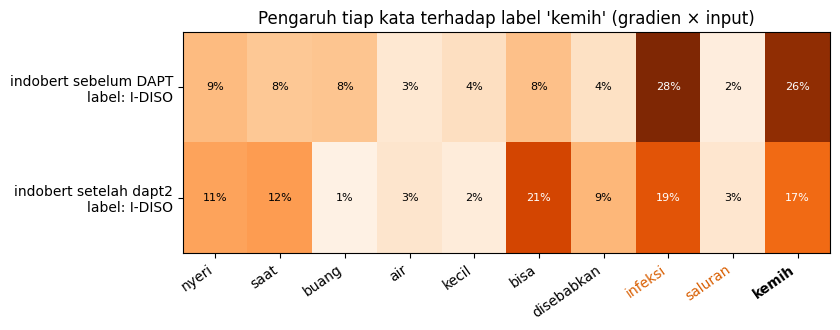

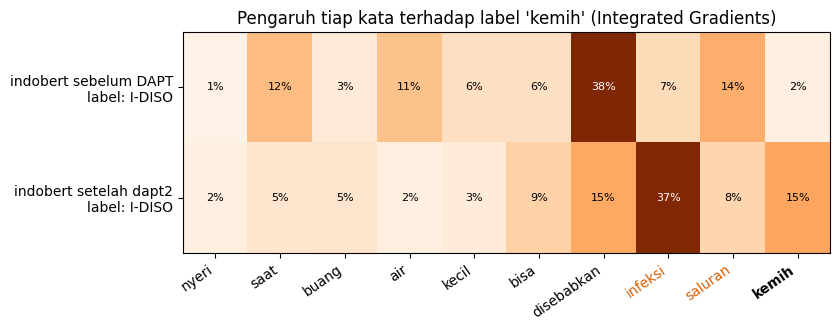

In [ ]:
KALIMAT = "nyeri saat buang air kecil bisa disebabkan infeksi saluran kemih"
words = split_words(KALIMAT)
t_idx = words.index("kemih")
span = [words.index("infeksi"), words.index("saluran"), t_idx]

res = [saliency(run, words, t_idx, "gxi") for run in XAI_RUNS]
for r in res:
    show(r, span)
heatmap(res, span, fname="naskah_kemih_gxi.png")
heatmap([saliency(run, words, t_idx, "ig") for run in XAI_RUNS], span, fname="naskah_kemih_ig.png")

## 5. Contoh nyata dari data test

Bagian ini mencari entitas di data test bioner_id yang **labelnya diperbaiki oleh DAPT**:

- entitas emas terdiri dari minimal 2 kata (misalnya "infeksi saluran kemih"),
- model sebelum DAPT salah melabeli entitas itu, dan model setelah DAPT melabelinya dengan benar.

Prediksi diambil dari run XAI di bagian 2, jadi modelnya sama persis dengan yang dianalisis. Kata target adalah **kata pertama yang salah dilabeli** model sebelum DAPT. Contoh: di "infeksi saluran kemih", model sebelum DAPT memberi `B-DISO` pada "kemih", jadi targetnya "kemih".

Sebagai pembanding, bagian ini juga mengambil entitas yang **dirusak** DAPT (sebelum benar, sesudah salah).

In [ ]:
def spans(tags):
    # Entitas emas sebagai (awal, akhir_inklusif, tipe). Entitas dimulai di B-X dan berlanjut selama I-X.
    out, i = [], 0
    while i < len(tags):
        if tags[i].startswith("B-"):
            typ, j = tags[i][2:], i
            while j + 1 < len(tags) and tags[j + 1] == f"I-{typ}":
                j += 1
            out.append((i, j, typ)); i = j + 1
        else:
            i += 1
    return out

def find_cases(before_run, after_run, min_len=2, max_cases=8, mode="diperbaiki"):
    key = before_run[0]
    b, a = XAI_RES[before_run], XAI_RES[after_run]
    toks = ner_dataset(key)["test"]["tokens"]
    cases, seen = [], set()
    for i, (true, pb, pa) in enumerate(zip(b["test_true"], b["test_pred"], a["test_pred"])):
        for s, e, typ in spans(true):
            if e - s + 1 < min_len:
                continue
            g = true[s:e + 1]
            ok_b, ok_a = pb[s:e + 1] == g, pa[s:e + 1] == g
            if (mode == "diperbaiki" and not ok_b and ok_a) or (mode == "dirusak" and ok_b and not ok_a):
                wrong = pb if mode == "diperbaiki" else pa
                t = next(k for k in range(s, e + 1) if wrong[k] != true[k])
                teks = " ".join(toks[i][s:e + 1])
                if teks.lower() in seen:
                    continue
                seen.add(teks.lower())
                cases.append(dict(chunk=i, words=toks[i], span=list(range(s, e + 1)), target_idx=t, tipe=typ,
                                  entitas=teks, emas=" ".join(g),
                                  sebelum=" ".join(pb[s:e + 1]), sesudah=" ".join(pa[s:e + 1])))
                if len(cases) >= max_cases:
                    return cases
    return cases

FIXED = find_cases(BEFORE, AFTER, mode="diperbaiki")
BROKEN = find_cases(BEFORE, AFTER, mode="dirusak")
cols = ["entitas", "tipe", "emas", "sebelum", "sesudah"]
print(f"Entitas multi-kata yang DIPERBAIKI DAPT (unik, maks 8): {len(FIXED)}")
display(pd.DataFrame(FIXED)[cols] if FIXED else "tidak ada")
print(f"Entitas multi-kata yang DIRUSAK DAPT (unik, maks 8): {len(BROKEN)}")
display(pd.DataFrame(BROKEN)[cols] if BROKEN else "tidak ada")

Entitas multi-kata yang DIPERBAIKI DAPT (unik, maks 8): 8


,entitas,tipe,emas,sebelum,sesudah
0,buang air kecil berdarah,DISO,B-DISO I-DISO I-DISO I-DISO,I-DISO I-DISO O B-DISO,B-DISO I-DISO I-DISO I-DISO
1,gangguan pada saluran pencernaan,DISO,B-DISO I-DISO I-DISO I-DISO,O O I-DISO O,B-DISO I-DISO I-DISO I-DISO
2,Sakit pada saat buang air kecil,DISO,B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO,O I-DISO I-DISO I-DISO I-DISO I-DISO,B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO
3,kandung kemih,ANAT,B-ANAT I-ANAT,B-ANAT I-DISO,B-ANAT I-ANAT
4,susah buang air besar,DISO,B-DISO I-DISO I-DISO I-DISO,B-DISO I-DISO I-DISO O,B-DISO I-DISO I-DISO I-DISO
5,perubahan hormon,DISO,B-DISO I-DISO,B-DISO O,B-DISO I-DISO
6,Radang Usus,DISO,B-DISO I-DISO,B-DISO B-DISO,B-DISO I-DISO
7,Nyeri perut,DISO,B-DISO I-DISO,B-DISO B-DISO,B-DISO I-DISO


Entitas multi-kata yang DIRUSAK DAPT (unik, maks 8): 8


,entitas,tipe,emas,sebelum,sesudah
0,air kencing,ANAT,B-ANAT I-ANAT,B-ANAT I-ANAT,I-ANAT I-ANAT
1,saluran kemih,ANAT,B-ANAT I-ANAT,B-ANAT I-ANAT,B-ANAT O
2,Nyeri perut,DISO,B-DISO I-DISO,B-DISO I-DISO,B-DISO O
3,kecemasan berlebihan,DISO,B-DISO I-DISO,B-DISO I-DISO,B-DISO O
4,Batu ginjal,DISO,B-DISO I-DISO,B-DISO I-DISO,B-DISO B-DISO
5,frekuensi buang air kecil yang meningkat,DISO,B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO,B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO,B-DISO B-DISO B-DISO B-DISO I-DISO I-DISO
6,pinggang bawah,ANAT,B-ANAT I-ANAT,B-ANAT I-ANAT,B-ANAT O
7,infeksi saluran kemih,DISO,B-DISO I-DISO I-DISO,B-DISO I-DISO I-DISO,B-DISO I-DISO B-DISO


### 5.1 Heatmap untuk tiap contoh yang diperbaiki

Kata di dalam entitas diberi warna oranye di sumbu bawah, dan kata target dicetak tebal. Yang dicari: apakah setelah DAPT porsi pengaruh berpindah ke kata lain di entitas yang sama.

[0] entitas: 'buang air kecil berdarah' | emas: B-DISO I-DISO I-DISO I-DISO | sebelum: I-DISO I-DISO O B-DISO | sesudah: B-DISO I-DISO I-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'buang': I-DISO
      terdapat O       ##                              0.3%
       riwayat O       ######                          0.8%
         buang I-DISO  #                               0.1%
           air I-DISO  ####                            0.5%
         kecil O       #                               0.1%
       seperti O       #                               0.1%
      berpasir I-DISO  ########                        1.0%
             , O       #                               0.1%
         buang I-DISO  ##############################  3.6%  <- target
           air I-DISO  ##                              0.2%  (frasa)
         kecil O                                       0.0%  (frasa)
      berdarah B-DISO  #                               0.1%  (frasa)
             , O                      

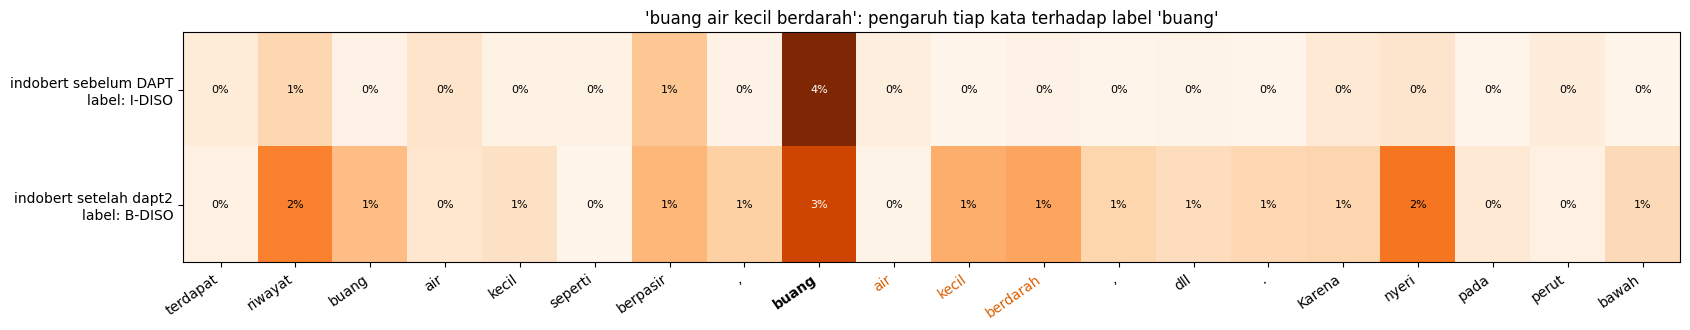

[1] entitas: 'gangguan pada saluran pencernaan' | emas: B-DISO I-DISO I-DISO I-DISO | sebelum: O O I-DISO O | sesudah: B-DISO I-DISO I-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'gangguan': O
          juga O                                       0.0%
         dapat O                                       0.0%
    disebabkan O                                       0.0%
          oleh O                                       0.1%
       infeksi B-DISO                                  0.1%
       saluran I-DISO                                  0.1%
         kemih I-DISO  #                               0.3%
          atau O                                       0.1%
      gangguan O       ##############################  8.4%  <- target
          pada O                                       0.0%  (frasa)
       saluran I-DISO  #                               0.2%  (frasa)
    pencernaan O       #                               0.2%  (frasa)
             . O                          

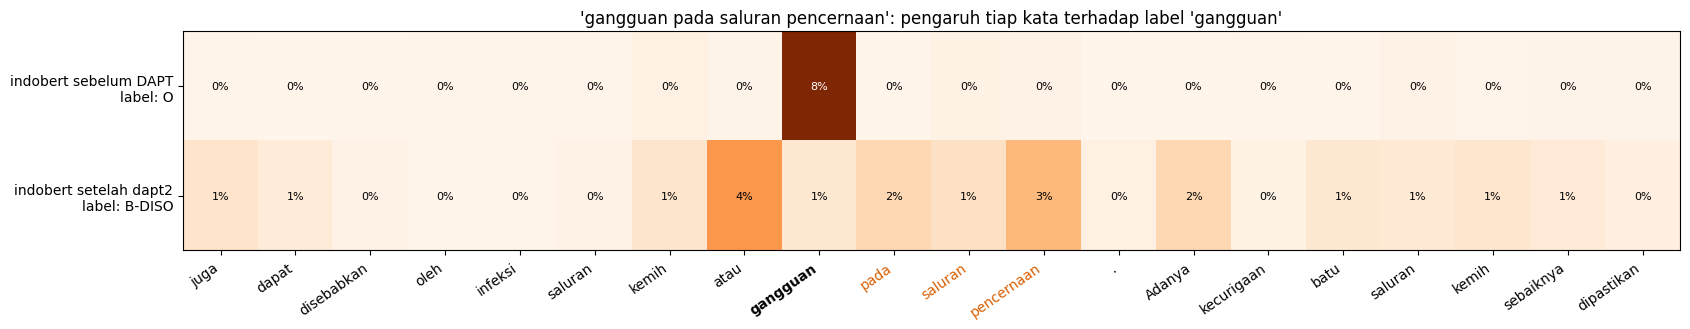

[2] entitas: 'Sakit pada saat buang air kecil' | emas: B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO | sebelum: O I-DISO I-DISO I-DISO I-DISO I-DISO | sesudah: B-DISO I-DISO I-DISO I-DISO I-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'Sakit': O
         malam O       ############################## 20.6%
             , O       ############                    8.5%
         Sakit O       ############                    8.5%  <- target
          pada I-DISO  ##                              1.7%  (frasa)
          saat I-DISO  #                               0.8%  (frasa)
         buang I-DISO  ##########                      7.2%  (frasa)
           air I-DISO  ##                              1.3%  (frasa)
         kecil I-DISO  #####                           3.6%  (frasa)
       umumnya O       #####                           3.5%
        sering O       ######                          3.9%
    disebabkan O       #                               1.0%
        karena O       ##           

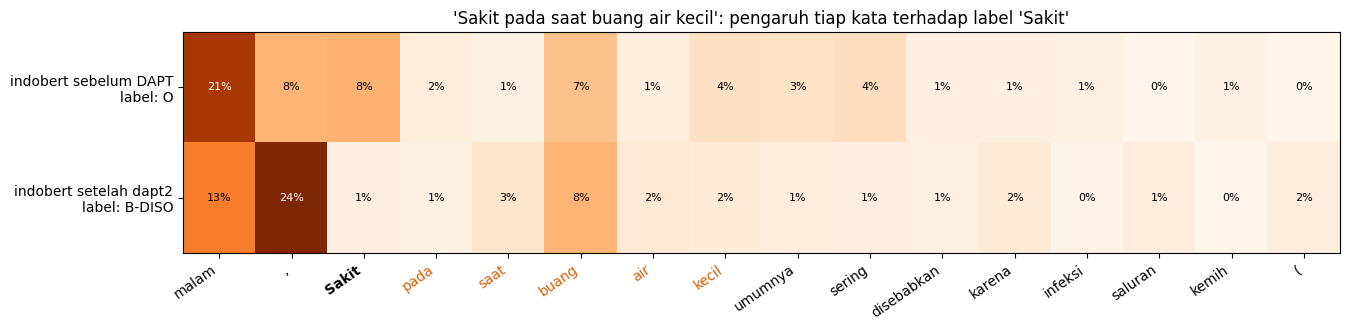

[3] entitas: 'kandung kemih' | emas: B-ANAT I-ANAT | sebelum: B-ANAT I-DISO | sesudah: B-ANAT I-ANAT
== indobert sebelum DAPT | gxi | label 'kemih': I-DISO
     perubahan O       #                               0.6%
        hormon I-DISO  #                               0.5%
           dan O                                       0.0%
   pertumbuhan O       #####                           1.9%
         rahim I-DISO  #                               0.5%
          yang O                                       0.0%
         dapat O                                       0.1%
       menekan O       #######                         2.6%
       kandung B-ANAT  ####                            1.7%  (frasa)
         kemih I-DISO  ############################## 11.9%  <- target
             , O                                       0.1%
      sehingga O       #                               0.6%
   menimbulkan O                                       0.2%
        sensai O       #######              

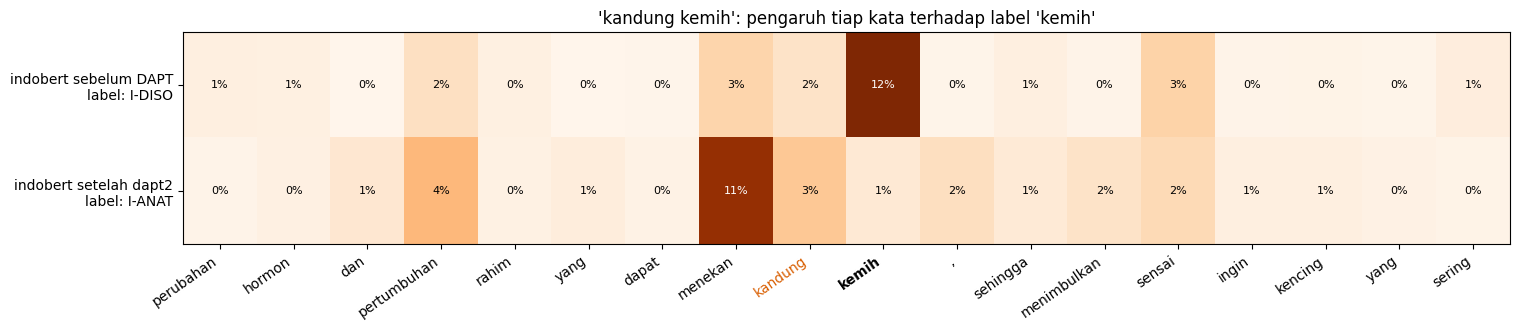

[4] entitas: 'susah buang air besar' | emas: B-DISO I-DISO I-DISO I-DISO | sebelum: B-DISO I-DISO I-DISO O | sesudah: B-DISO I-DISO I-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'besar': O
        selama O       #                               0.1%
          masa O                                       0.0%
     kehamilan B-DISO  #                               0.1%
     Hilangnya O       ###                             0.3%
         nafsu B-DISO  #####                           0.4%
         makan I-DISO  #                               0.1%
    Konstipasi B-DISO  #                               0.1%
          atau O                                       0.0%
         susah B-DISO  ####                            0.3%  (frasa)
         buang I-DISO  ##########                      0.9%  (frasa)
           air I-DISO  ##########                      0.9%  (frasa)
         besar O       ##############################  2.5%  <- target
        karena O       #######                

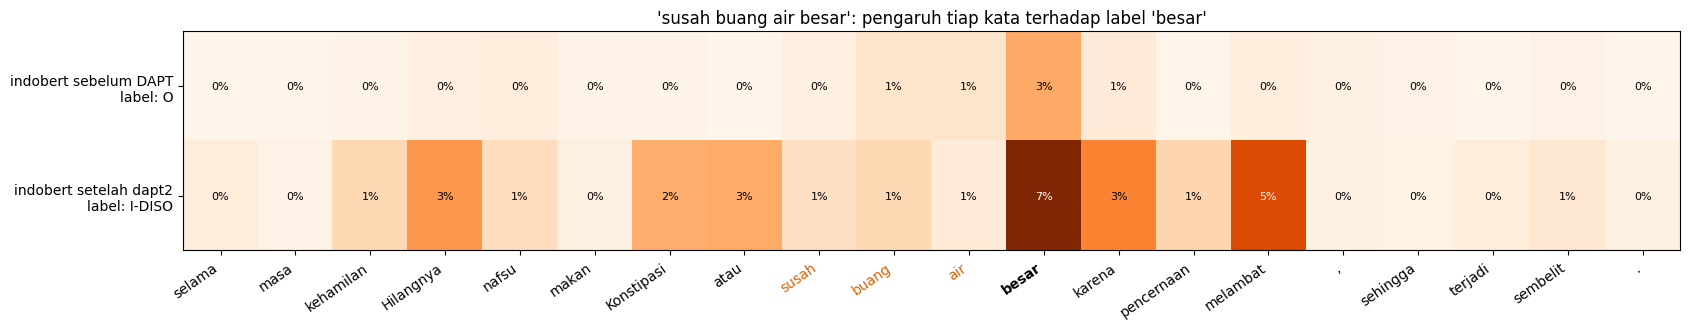

[5] entitas: 'perubahan hormon' | emas: B-DISO I-DISO | sebelum: B-DISO O | sesudah: B-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'hormon': O
       Suasana I-DISO  #                               0.3%
          Hati B-DISO  #                               0.2%
          yang O                                       0.1%
         mudah O                                       0.0%
       berubah O       ###                             0.7%
             , O                                       0.0%
   dipengaruhi O                                       0.0%
          oleh O                                       0.0%
     perubahan B-DISO  ####                            0.9%  (frasa)
        hormon O       ##############################  7.7%  <- target
        Pusing B-DISO                                  0.0%
     terkadang O       #                               0.2%
         dapat O                                       0.0%
     ditemukan O       ####                       

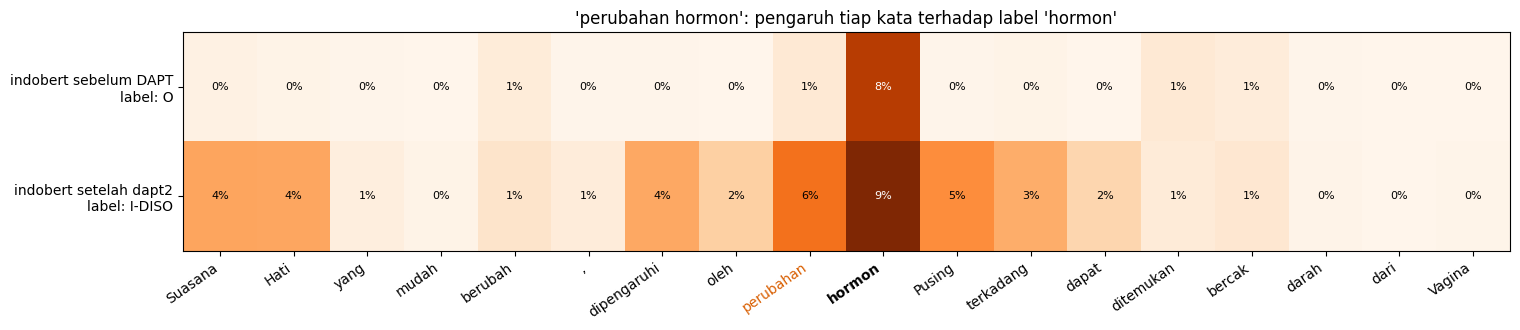

[6] entitas: 'Radang Usus' | emas: B-DISO I-DISO | sebelum: B-DISO B-DISO | sesudah: B-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'Usus': B-DISO
         perut I-DISO                                  0.0%
          juga O                                       0.0%
         dapat O                                       0.0%
    disebabkan O                                       0.1%
        karena O                                       0.0%
        adanya O                                       0.1%
         Diare B-DISO                                  0.1%
          atau O                                       0.1%
        Radang B-DISO  ####################            6.0%  (frasa)
          Usus B-DISO  ##############################  8.9%  <- target
             , O                                       0.1%
           dan O                                       0.0%
        Sering O                                       0.1%
         buang I-DISO                          

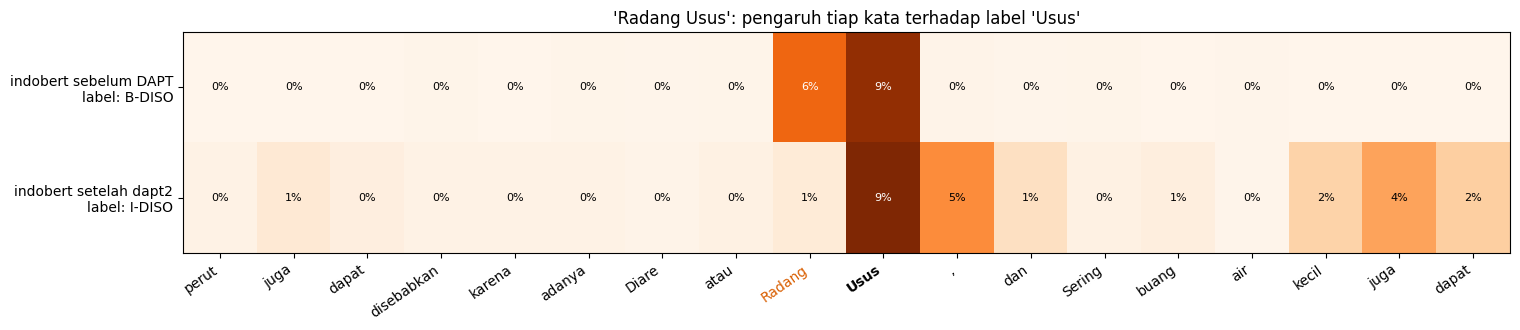

[7] entitas: 'Nyeri perut' | emas: B-DISO I-DISO | sebelum: B-DISO B-DISO | sesudah: B-DISO I-DISO
== indobert sebelum DAPT | gxi | label 'perut': B-DISO
       keluhan O                                       0.0%
          yang O                                       0.1%
     dirasakan O                                       0.0%
             . O                                       0.0%
      Beberapa O                                       0.1%
       Kondisi O                                       0.1%
        dengan O                                       0.0%
        gejala O                                       0.0%
         Nyeri B-DISO  #                               0.7%  (frasa)
         perut B-DISO  ############################## 17.6%  <- target
           dan O                                       0.0%
        sering I-DISO                                  0.1%
         buang I-DISO                                  0.2%
           air I-DISO                         

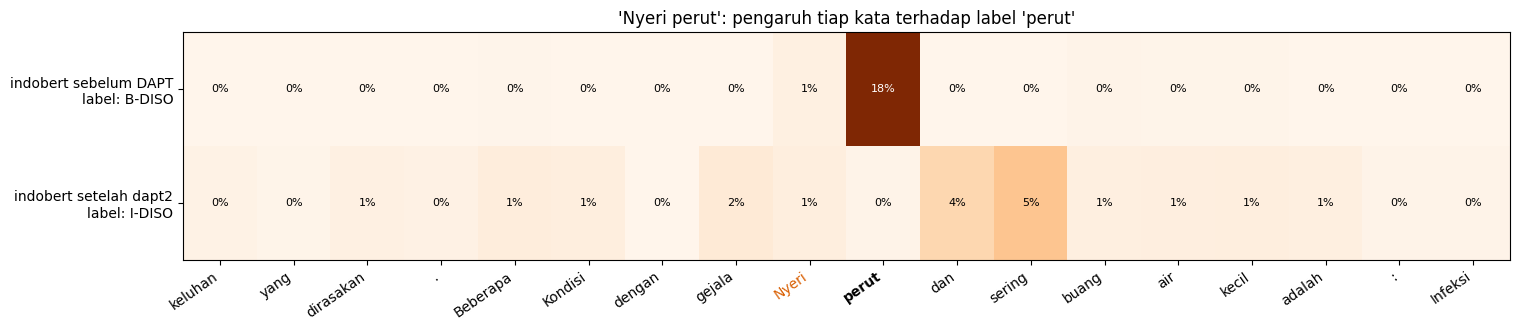

In [ ]:
for n, c in enumerate(FIXED):
    res = [saliency(run, c["words"], c["target_idx"], "gxi") for run in XAI_RUNS]
    print(f"[{n}] entitas: '{c['entitas']}' | emas: {c['emas']} | sebelum: {c['sebelum']} | sesudah: {c['sesudah']}")
    for r in res:
        show(r, c["span"])
    heatmap(res, c["span"], fname=f"test_diperbaiki_{n}.png",
            title=f"'{c['entitas']}': pengaruh tiap kata terhadap label '{c['words'][c['target_idx']]}'")

## 6. Ringkasan untuk slide

Untuk setiap contoh dihitung tiga porsi pengaruh (jumlahnya 100%):

- **target**: dari kata target itu sendiri,
- **frasa**: dari kata lain di entitas yang sama,
- **konteks lain**: dari kata di luar entitas.

Kalau hipotesis benar, porsi **frasa** pada contoh yang diperbaiki naik setelah DAPT, dan arahnya sama untuk kedua metode.

In [ ]:
def shares(r, span):
    t = r["target_idx"]
    frasa = sum(r["scores"][i] for i in span if i != t)
    return r["scores"][t], frasa, 1 - r["scores"][t] - frasa

rows = []
groups = [("naskah", [dict(words=split_words(KALIMAT), target_idx=t_idx, span=span, entitas="infeksi saluran kemih")]),
          ("diperbaiki", FIXED), ("dirusak", BROKEN)]
for grup, cases in groups:
    for c in cases:
        for run in XAI_RUNS:
            for method in ["gxi", "ig"]:
                r = saliency(run, c["words"], c["target_idx"], method)
                st, sf, sk = shares(r, c["span"])
                rows.append(dict(grup=grup, entitas=c["entitas"], model=run_name(*run), metode=method,
                                 label_target=r["label"], target=st, frasa=sf, konteks=sk))
DF = pd.DataFrame(rows)
DF.to_csv(f"{XAI_FIG}/saliency_per_contoh.csv", index=False)

pct = {c: "{:.1%}" for c in ["target", "frasa", "konteks"]}
SUMMARY = DF.groupby(["grup", "metode", "model"], sort=False)[["target", "frasa", "konteks"]].mean()
display(SUMMARY.style.format("{:.1%}"))

nb, na = run_name(*BEFORE), run_name(*AFTER)
for grup in ["diperbaiki", "dirusak"]:
    for m in ["gxi", "ig"]:
        p = DF[(DF.grup == grup) & (DF.metode == m)].pivot_table(index="entitas", columns="model", values="frasa")
        if len(p):
            naik = int((p[na] > p[nb]).sum())
            print(f"{grup:10s} {m}: porsi frasa naik setelah DAPT di {naik} dari {len(p)} entitas")

diperbaiki gxi: porsi frasa naik setelah DAPT di 7 dari 8 entitas
diperbaiki ig: porsi frasa naik setelah DAPT di 7 dari 8 entitas
dirusak    gxi: porsi frasa naik setelah DAPT di 4 dari 8 entitas
dirusak    ig: porsi frasa naik setelah DAPT di 4 dari 8 entitas


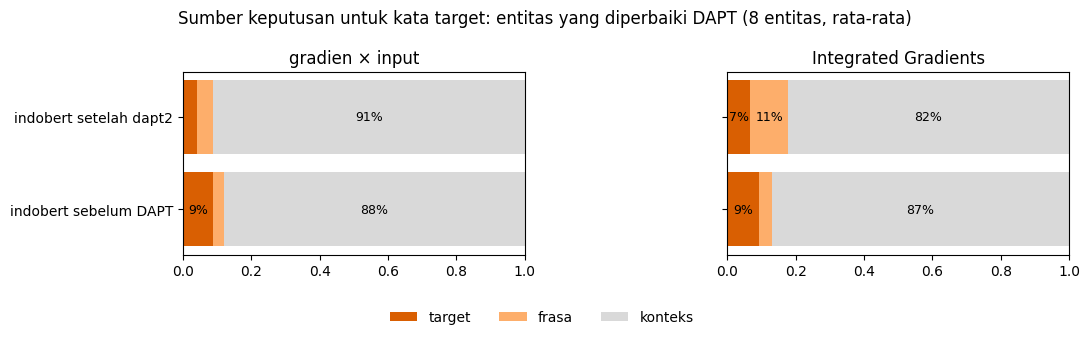

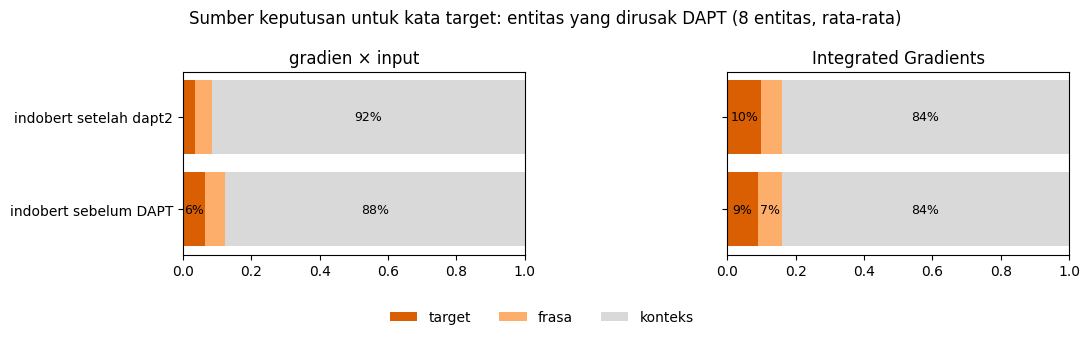

In [ ]:
def plot_summary(grup, fname):
    sub = SUMMARY.loc[grup] if grup in SUMMARY.index.get_level_values(0) else None
    if sub is None:
        print("tidak ada data untuk", grup); return
    n = DF[(DF.grup == grup)].entitas.nunique()
    fig, axes = plt.subplots(1, 2, figsize=(11, 1.2 * len(XAI_RUNS) + 1.6), sharey=True)
    colors = ["#d95f02", "#fdae6b", "#d9d9d9"]
    order = [run_name(*r) for r in XAI_RUNS]
    for ax, m in zip(axes, ["gxi", "ig"]):
        s = sub.loc[m].reindex(order)
        left = np.zeros(len(s))
        for col, c in zip(s.columns, colors):
            ax.barh(range(len(s)), s[col], left=left, color=c, label=col)
            for i, v in enumerate(s[col]):
                if v > 0.06:
                    ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9)
            left += s[col].values
        ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index); ax.set_xlim(0, 1); ax.invert_yaxis()
        ax.set_title("gradien × input" if m == "gxi" else "Integrated Gradients")
    axes[0].legend(loc="lower center", bbox_to_anchor=(1.05, -0.45), ncol=3, frameon=False)
    fig.suptitle(f"Sumber keputusan untuk kata target: entitas yang {grup} DAPT ({n} entitas, rata-rata)")
    plt.tight_layout()
    fig.savefig(f"{XAI_FIG}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

plot_summary("diperbaiki", "ringkasan_diperbaiki.png")
plot_summary("dirusak", "ringkasan_dirusak.png")

### 6.1 Cek kestabilan: apakah dua metode sepakat?

Korelasi peringkat (Spearman) antara skor gradien × input dan IG, dihitung pada jendela kata di sekitar target. Kalau rata-ratanya tinggi (misalnya di atas 0,7), urutan kata penting tidak bergantung pada metode, jadi hasilnya lebih aman dipresentasikan.

In [ ]:
def spearman(a, b):
    ra, rb = pd.Series(a).rank().values, pd.Series(b).rank().values
    return float(np.corrcoef(ra, rb)[0, 1])

rows = []
for grup, cases in groups:
    for c in cases:
        for run in XAI_RUNS:
            g = saliency(run, c["words"], c["target_idx"], "gxi")
            i = saliency(run, c["words"], c["target_idx"], "ig")
            lo, hi = window(g, c["span"])
            rows.append(dict(grup=grup, entitas=c["entitas"], model=run_name(*run),
                             spearman=spearman(g["scores"][lo:hi], i["scores"][lo:hi])))
STAB = pd.DataFrame(rows)
display(STAB.groupby(["grup", "model"], sort=False)["spearman"].agg(["mean", "min", "count"]).round(2))

mean   min  count
grup       model                                    
naskah     indobert sebelum DAPT  -0.70 -0.70      1
           indobert setelah dapt2  0.49  0.49      1
diperbaiki indobert sebelum DAPT   0.66  0.34      8
           indobert setelah dapt2  0.38  0.01      8
dirusak    indobert sebelum DAPT   0.42  0.22      8
           indobert setelah dapt2  0.59  0.45      8

## 7. Cara membaca hasil dan batasannya

**Hipotesis didukung** kalau pada contoh yang *diperbaiki* porsi **frasa** naik setelah DAPT di sebagian besar entitas, untuk kedua metode, dan korelasi kedua metode cukup tinggi.

**Hipotesis tidak didukung** kalau porsinya tidak berubah atau arahnya berbeda antara gradien × input dan IG. Ini juga hasil yang sah untuk dilaporkan. Artinya perbaikan label datang dari perubahan yang tidak terlihat lewat saliency per kata.

**Batasan yang perlu disebut di slide:**
- Saliency menunjukkan **korelasi lokal** antara input dan skor label, bukan penjelasan sebab-akibat yang lengkap.
- Hanya seed 42 dan beberapa entitas. Ini ilustrasi, bukan uji statistik.
- IndoBERT setelah DAPT berawal dari head MLM acak (Gap 3 di naskah), jadi perubahan encoder bisa ikut dipengaruhi hal itu.
- Sebagian label emas bioner_id janggal (8,5 sampai 12,6%). Jadi "diperbaiki" dan "dirusak" dinilai terhadap label emas yang tidak selalu konsisten.
- Untuk model dengan tokenizer yang memecah kata, skor kata adalah jumlah skor subword. Kata yang terpecah jadi banyak subword bisa terlihat sedikit lebih "penting".

Gambar dan tabel tersimpan di `CP2/reports/figures/xai/`.